## Module - 5

### Module End Project: Deep Learning Applications 


### Project Title: AI-Based Image Classification System Using Deep Learning


### Task 1 – Data Preparation


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.22.0-rc1


In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [3]:
print("Data Type:", x_train.dtype)
print("Minimum Pixel Value:", x_train.min())
print("Maximum Pixel Value:", x_train.max())

print("Unique Classes:", np.unique(y_train))

Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255
Unique Classes: [0 1 2 3 4 5 6 7 8 9]


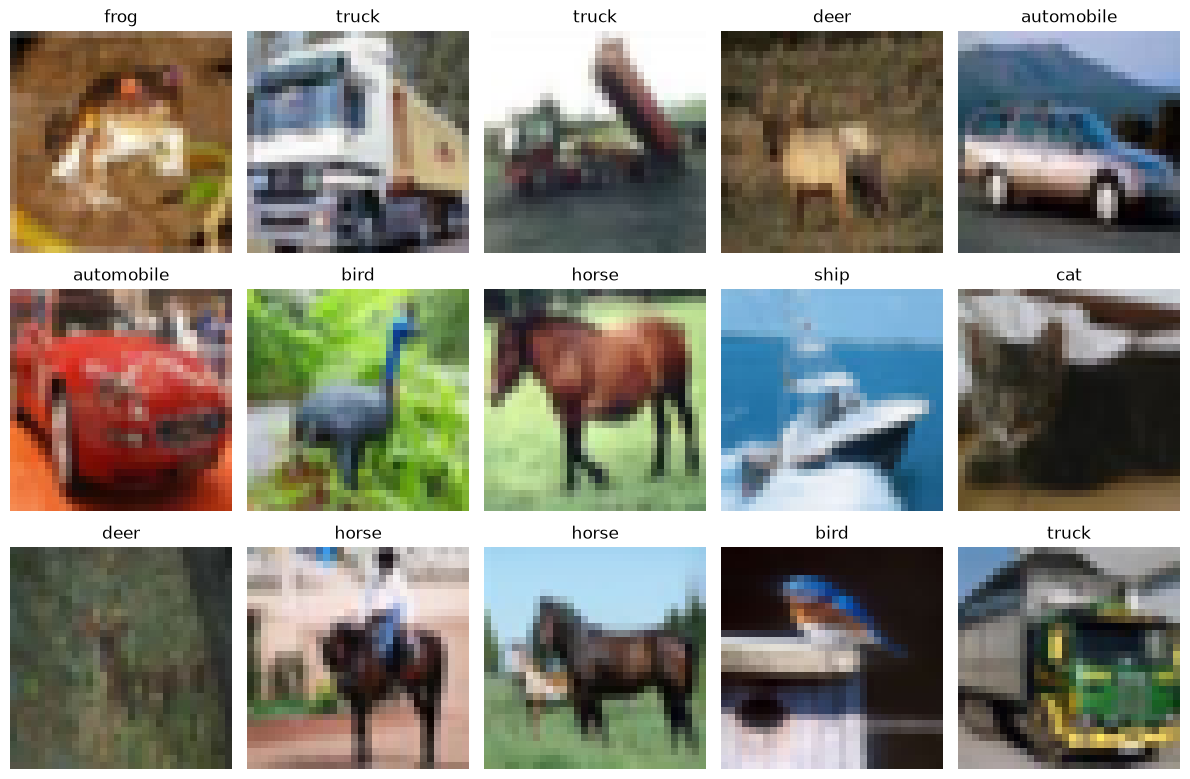

In [4]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(12, 8))

for i in range(15):

    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i])

    label = int(y_train[i][0])

    plt.title(class_names[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Labels: (50000,)
Testing Labels: (10000,)


In [6]:
x_train = x_train.astype('float32') / 255.0

x_test = x_test.astype('float32') / 255.0

print("Minimum:", x_train.min())
print("Maximum:", x_train.max())
print("Data Type:", x_train.dtype)

Minimum: 0.0
Maximum: 1.0
Data Type: float32


In [7]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Testing:", x_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Testing: (10000, 32, 32, 3) (10000,)


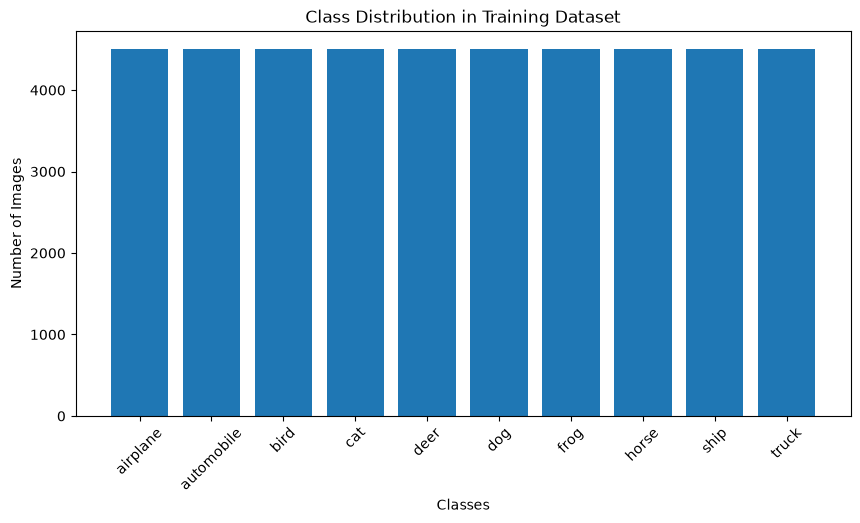

In [8]:
unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))

plt.bar(
    [class_names[i] for i in unique],
    counts
)

plt.title("Class Distribution in Training Dataset")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.show()

In [9]:
print("========== FINAL DATASET ==========")

print("Training Images:", len(x_train))
print("Validation Images:", len(x_val))
print("Testing Images:", len(x_test))

print("Image Shape:", x_train.shape[1:])

print("Number of Classes:", len(class_names))

print("Normalized Pixel Range:",
      x_train.min(), "to", x_train.max())

========== FINAL DATASET ==========
Training Images: 45000
Validation Images: 5000
Testing Images: 10000
Image Shape: (32, 32, 3)
Number of Classes: 10
Normalized Pixel Range: 0.0 to 1.0


In [ ]:
np.savez_compressed(
    "cifar10_preprocessed.npz",

    x_train=x_train,
    y_train=y_train,

    x_val=x_val,
    y_val=y_val,

    x_test=x_test,
    y_test=y_test
)

print("Dataset saved successfully!")

Dataset saved successfully!
